In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.decomposition import PCA
from sklearn.svm import SVC
import time
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

In [2]:
N_COMPONENTS = 150

**Dataset Loading and Initial Exploration**

* **Data Fetching:** The `fetch_lfw_people` function loads the dataset, utilizing `min_faces_per_person=70` to exclude individuals with insufficient data for robust training, and `resize=0.4` to downscale images, which significantly reduces the dimensionality and computational load.
* **Feature Extraction:** The code extracts the flattened 1D pixel vectors into the feature matrix `X` and the target labels into `y`, while preserving the original 2D image dimensions (`h`, `w`) for future visualization.
* **Class Imbalance Check:** The final loop iterates through the target names to count and print the number of images per person, exposing the severe unequal distribution of classes that must be addressed during model training.

In [3]:
lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)

n_samples, h, w, = lfw_people.images.shape
X = lfw_people.data
y = lfw_people.target
target_names = lfw_people.target_names
n_classes = target_names.shape[0]

print(f"Image amount: {n_samples}")
print(f"Single image shape: {h} x {w}")
print(f"Number of features (1d pixels): {X.shape[1]}")
print(f"Class amount: {n_classes} \n")

print("Images per class: ")
for i, name in enumerate(target_names):
    count = sum(y == i)
    print(f"{name}: {count} images")

Image amount: 1288
Single image shape: 50 x 37
Number of features (1d pixels): 1850
Class amount: 7 

Images per class: 
Ariel Sharon: 77 images
Colin Powell: 236 images
Donald Rumsfeld: 121 images
George W Bush: 530 images
Gerhard Schroeder: 109 images
Hugo Chavez: 71 images
Tony Blair: 144 images


**Data Splitting and Dimensionality Reduction (PCA)**

* **Stratified Split:** `train_test_split` divides the dataset into training (75%) and testing (25%) sets. The `stratify=y` parameter is critical here, as it preserves the heavily imbalanced class proportions in both splits.
* **PCA Configuration:** `PCA` reduces the high-dimensional pixel space down to `N_COMPONENTS` (eigenfaces). `svd_solver="randomized"` speeds up computation for large matrices, while `whiten=True` scales the extracted components to unit variance, which is highly beneficial for the convergence and performance of the downstream SVM model.
* **Preventing Data Leakage:** `pca.fit()` is applied exclusively to `X_train` so the model does not "see" the test set during feature extraction. Both sets are then projected into the lower-dimensional space using `transform()`.
* **Explained Variance Check:** The sum of `explained_variance_ratio_` calculates the exact percentage of original image information (variance) successfully retained after compression.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

pca = PCA(n_components=N_COMPONENTS, svd_solver="randomized", whiten=True, random_state=42)
pca.fit(X_train)

X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

explained_variance = sum(pca.explained_variance_ratio_)
print(f"{N_COMPONENTS} components keeps {explained_variance * 100:.1f}% information from original data")

150 components keeps 94.6% information from original data


**Eigenfaces Visualization**

* **Component Reshaping:** `pca.components_` contains the principal axes (eigenvectors) extracted from the training data. Reshaping these 1D arrays back to the original 2D image dimensions (`h`, `w`) allows us to visualize the "eigenfaces" — the foundational visual building blocks (like lighting gradients and structural facial features) the model uses to represent any face.
* **Plotting Helper Function:** `plot_gallery` is a custom Matplotlib utility function that arranges the images into a structured grid. It removes axis ticks (`xticks(())`, `yticks(())`) and applies a grayscale colormap (`cmap=plt.cm.gray`) for clean, distortion-free visual inspection.
* **Model Insights:** Displaying these components provides intuitive interpretability of the PCA step, demonstrating exactly what abstract features the downstream SVM classifier will evaluate instead of raw pixels.

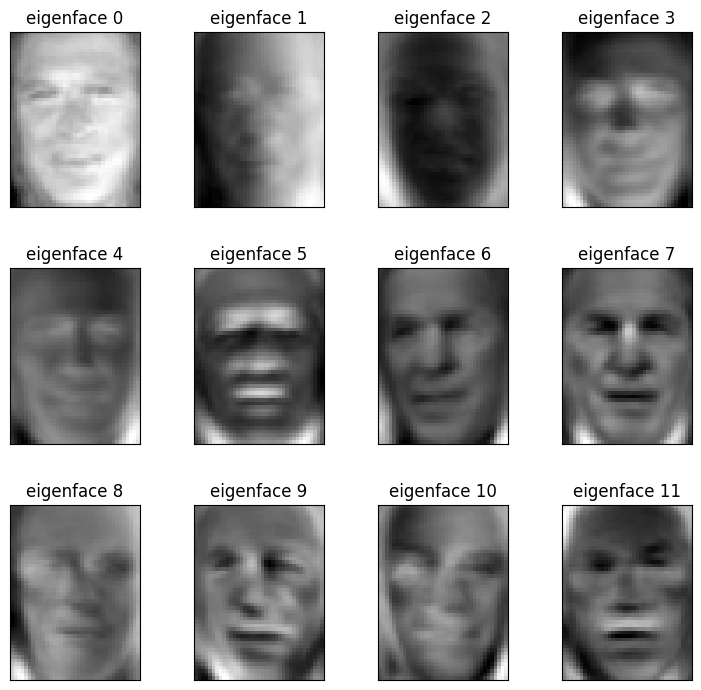

In [5]:
eigenfaces = pca.components_.reshape((N_COMPONENTS, h, w))

def plot_gallery(images, titles, h, w, n_row=3, n_col=4):
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    plt.subplots_adjust(bottom=0, left=.01, right=.99, top=.90, hspace=.35)

    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i+1)
        plt.imshow(images[i].reshape((h, w)), cmap=plt.cm.gray)
        plt.title(titles[i], size=12)
        plt.xticks(())
        plt.yticks(())
    
    plt.show()

eigenface_titles = [f"eigenface {i}" for i in range(eigenfaces.shape[0])]

plot_gallery(eigenfaces, eigenface_titles, h, w)

**SVM Training and Hyperparameter Optimization**

* **Hyperparameter Grid:** `param_grid` defines the search space for the SVM. It tests various combinations of `C` (regularization parameter controlling the margin hardness) and `gamma` (defines the influence radius of single training examples in the RBF kernel).
* **Model Configuration:** Initializes a Support Vector Classifier (`SVC`) with a non-linear `rbf` kernel. The inclusion of `class_weight='balanced'` is critical — it automatically adjusts weights inversely proportional to class frequencies, penalizing mistakes on minority classes heavier to prevent the model from always guessing the majority class.
* **Exhaustive Search:** `GridSearchCV` evaluates every parameter combination using 5-fold cross-validation (`cv=5`) to ensure robust, generalized performance. Setting `n_jobs=-1` parallelizes the computation across all available CPU cores to speed up the process.
* **Execution & Output:** `clf.fit` trains the models on the reduced `X_train_pca` dataset, and the code finally outputs the absolute best estimator found during the grid search along with the total execution time.

In [6]:
t0 = time.time()

param_grid = {
    'C': [1e3, 5e3, 1e4, 5e4, 1e5],
    'gamma': [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.1],
}

clf = GridSearchCV(
    SVC(kernel='rbf', class_weight='balanced'), param_grid, cv=5, n_jobs=-1
)

clf.fit(X_train_pca, y_train)

print(f"Training and optimisation took {time.time() - t0:.1f} seconds.")
print("Best estimtor chosen by GridSearch:")
print(clf.best_estimator_)

Training and optimisation took 11.1 seconds.
Best estimtor chosen by GridSearch:
SVC(C=1000.0, class_weight='balanced', gamma=0.005)


**Model Evaluation and Results Interpretation**

* **Test Set Inference:** `clf.predict` evaluates the optimized SVM model on `X_test_pca`, simulating how the system performs on completely unseen images.
* **Classification Report:** Generates a detailed metric breakdown. 
    * *How to interpret:* Because the dataset is heavily imbalanced, do not rely on overall `accuracy`. Instead, analyze the `F1-score` and `Recall` for minority classes. A high recall means the model successfully identifies most pictures of a specific person, while a high precision means that when it predicts a person, it is usually correct.
* **Confusion Matrix:** `ConfusionMatrixDisplay` creates a visual heatmap comparing true identities against model predictions.
    * *How to interpret:* Perfect predictions fall strictly on the diagonal line. Off-diagonal numbers represent specific misclassifications. Look closely at the column of the majority class (e.g., George W. Bush) — high numbers off the diagonal here indicate that the model still slightly biases towards the most common person when it is uncertain, despite the balanced class weights.
* **Visual Verification:** The custom `title` function formats the text (extracting just the surname for readability), and `plot_gallery` displays a grid of actual test images with their predicted

Classification report:
                   precision    recall  f1-score   support

     Ariel Sharon       0.93      0.68      0.79        19
     Colin Powell       0.90      0.93      0.92        59
  Donald Rumsfeld       0.87      0.67      0.75        30
    George W Bush       0.81      0.98      0.88       133
Gerhard Schroeder       0.91      0.74      0.82        27
      Hugo Chavez       1.00      0.61      0.76        18
       Tony Blair       0.97      0.81      0.88        36

         accuracy                           0.86       322
        macro avg       0.91      0.77      0.83       322
     weighted avg       0.87      0.86      0.86       322

Confusion matrix


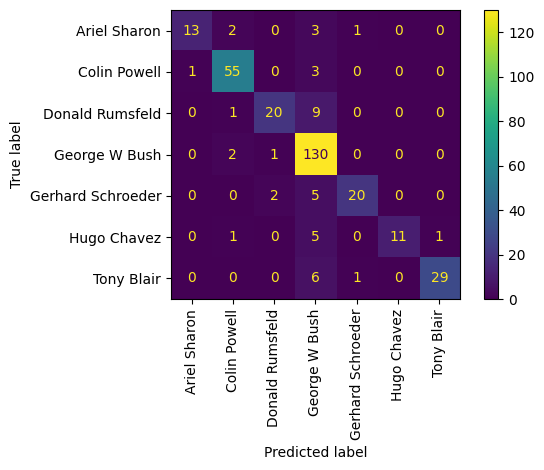


Example fredictions on test data:


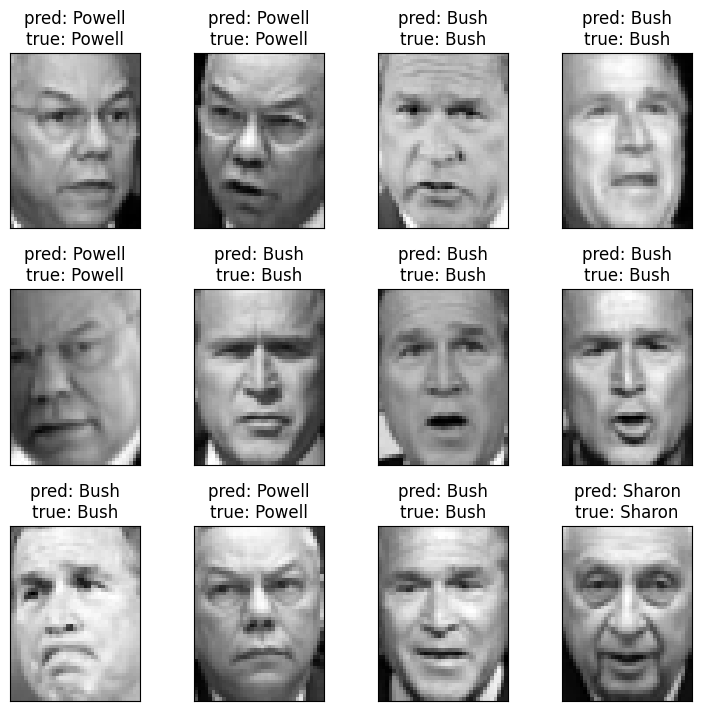

In [7]:
y_pred = clf.predict(X_test_pca)

print("Classification report:")
print(classification_report(y_test, y_pred, target_names=target_names))


print("Confusion matrix")
ConfusionMatrixDisplay.from_estimator(
    clf, X_test_pca, y_test, display_labels=target_names, xticks_rotation='vertical'
)
plt.tight_layout()
plt.show()

def title(y_pred, y_test, target_names, i):
    pred_name = target_names[y_pred[i]].rsplit(' ', 1)[-1]
    true_name = target_names[y_test[i]].rsplit(' ', 1)[-1]
    return f'pred: {pred_name}\ntrue: {true_name}'

prediction_titles = [title(y_pred, y_test, target_names, i)
                     for i in range(y_pred.shape[0])]

print("\nExample fredictions on test data:")
plot_gallery(X_test, prediction_titles, h, w)